# Sea ice segmentation: Adaptive threshold binarization
The most recent update to the IFT improved the imgradient function, the k-means segmentation and binarization, and the method for selecting bright ice pixels. Here, I'll show how the k-means segmentation and ice detection work, and then apply a simple test to the watershed result to see if that can be improved sufficiently.

Some notes here:
* Performance will depend on the preprocessing results
* We want to find a global value for $k$, likely just in the range of k=2-6.
* The ideal result will have the following characteristics
  * High recall (floes are detected)
  * Moderately high precision (we expect some interstial ice)
  * Good alignment with edges in the original image
* The floe splitting step could be considered part of the algorithm to refine, or a separate step.

Here I'll load in a sample of cases with visible sea ice floes, and test the k-means binarization.

In [1]:
using Pkg
Pkg.activate("calval")
Pkg.update(; name="IceFloeTracker", rev="main")
using IceFloeTracker
using Images
using Random
using DataFrames
using Plots
using StatsBase

  Activating project at `~/Documents/research/calval_tgrs/notebooks/calval`
    Updating registry at `~/.julia/registries/General.toml`
    Updating git-repo `https://github.com/WilhelmusLab/IceFloeTracker.jl.git`
     Project No packages added to or removed from `~/Documents/research/calval_tgrs/notebooks/calval/Project.toml`
    Manifest No packages added to or removed from `~/Documents/research/calval_tgrs/notebooks/calval/Manifest.toml`


In [2]:
dataset = Watkins2026Dataset(ref="v0.2") # [6, 13, 61, 25, 121, 150]
case = filter(f -> f.case_number in [6, 11, 63, 111, 138, 166]  && f.satellite=="aqua", dataset)

Dataset(GitHubLoader("https://github.com/danielmwatkins/ice-floe-validation-dataset/", "v0.2", "/tmp/Watkins2026"), 6×26 DataFrame
 Row │        case_number  region         satellite  start_date  pass_time     ⋯
     │ Int64  Int64        String         String     Dates.Date  DateTime      ⋯
─────┼──────────────────────────────────────────────────────────────────────────
   1 │    11            6  baffin_bay     aqua       2022-05-30  2022-05-30T15 ⋯
   2 │    20           11  baffin_bay     aqua       2011-07-02  2011-07-02T16
   3 │   124           63  beaufort_sea   aqua       2007-07-11  2007-07-11T19
   4 │   220          111  greenland_sea  aqua       2012-06-23  2012-06-23T11
   5 │   274          138  hudson_bay     aqua       2020-05-09  2020-05-09T17 ⋯
   6 │   330          166  laptev_sea     aqua       2016-09-04  2016-09-04T00
                                                              21 columns omitted)

In [3]:
case.info[:, ["case_number", "region", "satellite", "maximum_floe_size"]]

Row,case_number,region,satellite,maximum_floe_size
,Int64,String,String,Float64?
1,6,baffin_bay,aqua,3461.0
2,11,baffin_bay,aqua,1293.0
3,63,beaufort_sea,aqua,9808.0
4,111,greenland_sea,aqua,2282.0
5,138,hudson_bay,aqua,1057.0
6,166,laptev_sea,aqua,1308.0


In [4]:
case.info.maximum_floe_size

6-element Vector{Union{Missing, Float64}}:
 3461.0
 1293.0
 9808.0
 2282.0
 1057.0
 1308.0

In [5]:
abstract type IceFloePreprocessingAlgorithm end

@kwdef struct Preprocess <: IceFloePreprocessingAlgorithm
    diffusion_algorithm = PeronaMalikDiffusion(λ=0.1, K=0.1, niters=5, g="exponential")
    adapthisteq_params = (nbins=256, rblocks=8, cblocks=8, clip=0.99) # rblocks/cblocks not used yet -- add with CLAHE.jl
    unsharp_mask_params = (radius=50, amount=0.2, threshold=0.01)
end

function (p::Preprocess)(
    truecolor_image::AbstractArray{<:Union{AbstractRGB,TransparentRGB}}, 
    landmask,
    cloud_mask,
    tiles
)
    # Cast to grayscale first to save compute time
    proc_img = Gray.(truecolor_image)
    apply_landmask!(proc_img, landmask .|| cloud_mask)

    # Diffusion and sharpening
    for tile in tiles
        proc_img[tile...] .= nonlinear_diffusion(proc_img[tile...], p.diffusion_algorithm)
    end
    
    adjust_histogram!(proc_img,
        ContrastLimitedAdaptiveHistogramEqualization(
            nbins=p.adapthisteq_params.nbins,
            rblocks=p.adapthisteq_params.rblocks,
            cblocks=p.adapthisteq_params.cblocks,
            clip=p.adapthisteq_params.clip)
    )

    for tile in tiles
        proc_img[tile...] .= unsharp_mask(proc_img[tile...],
                p.unsharp_mask_params.radius,
                p.unsharp_mask_params.amount,
                p.unsharp_mask_params.threshold)
    end

            
    apply_landmask!(proc_img, landmask .|| cloud_mask)
    
    return proc_img
end

function se_disk(r)
    se = [sum(abs.(c.I .- (r + 1)) .^ 2) for c in CartesianIndices((2*r + 1, 2*r + 1))]
    return sqrt.(se) .<= r
end


se_disk (generic function with 1 method)

In [14]:
truecolor_image = modis_truecolor.(case)
falsecolor_image = modis_falsecolor.(case)
land_mask = modis_landmask.(case)
land_mask = BitMatrix[Gray.(r) .> 0 for r in land_mask]
cloud_mask = Watkins2025CloudMask().(falsecolor_image)
coastal_buffer = create_coastal_buffer_mask.(land_mask, [strel_box((51,51))])
tiles = get_tiles(truecolor_image[1], 400) # Cal-val paper may or may not include the tiling portion...
proc_gray = Preprocess().(truecolor_image, cloud_mask, land_mask, [tiles]);

prelim_ice = IceDetectionBrightnessPeaksMODIS134(band_1_min=0.3)

# Mask images before k-means, preliminary ice mask application
tc_masked = apply_landmask.(truecolor_image, cloud_mask)
tc_masked .= apply_landmask.(tc_masked, land_mask)
fc_masked = apply_landmask.(falsecolor_image, cloud_mask)
fc_masked .= apply_landmask.(fc_masked, coastal_buffer)
prelim_ice_mask = prelim_ice.(tc_masked)


6-element Vector{BitMatrix}:
 [0 1 … 1 1; 0 0 … 1 1; … ; 1 1 … 1 1; 1 1 … 1 1]
 [0 0 … 1 1; 0 0 … 1 1; … ; 0 0 … 1 1; 0 0 … 1 1]
 [1 1 … 1 0; 1 1 … 1 1; … ; 1 1 … 1 1; 1 1 … 1 1]
 [1 1 … 1 1; 1 1 … 1 1; … ; 1 1 … 1 1; 1 1 … 1 1]
 [1 1 … 1 1; 1 1 … 1 1; … ; 0 0 … 0 0; 0 0 … 0 0]
 [1 1 … 1 0; 1 1 … 1 1; … ; 1 1 … 1 1; 1 1 … 1 1]

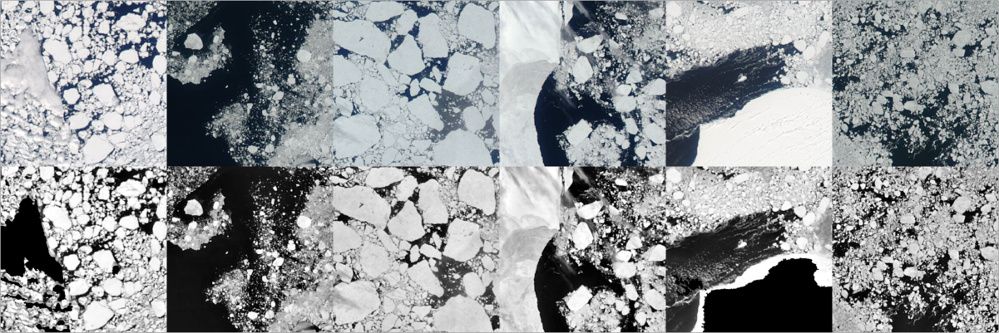

In [7]:
mosaicview(mosaicview(truecolor_image..., nrow=1),
           mosaicview(proc_gray..., nrow=1), nrow=2)

# Adaptive threshold binarization
- Worth checking whether the tiling is helpful or not. I think the main thing is so that we can skip empty tiles

In [8]:
fc_masked = apply_landmask.(falsecolor_image, cloud_mask)
fc_masked .= apply_landmask.(fc_masked, coastal_buffer)
algo = IceDetectionBrightnessPeaksMODIS721(band_7_max=0.1, possible_ice_threshold=0.3; join_method="union")
tiles = get_tiles(fc_masked[1], 400)
adaptive_result = tiled_adaptive_binarization.(proc_gray, [tiles]; minimum_window_size=200, threshold_percentage=0)
adaptive_result = [a .> 0 for a in adaptive_result];

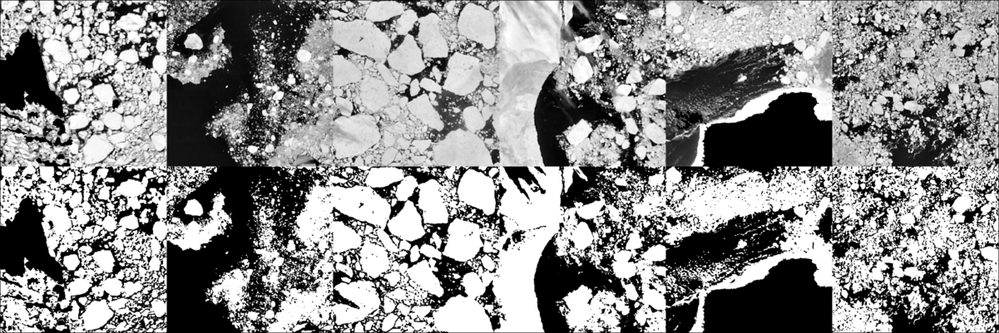

In [9]:
mosaicview(mosaicview(proc_gray..., nrow=1),
           mosaicview([Gray.(img) for img in adaptive_result], nrow=1))

In [10]:
# Function from LA2019
# Not clear that this function can be effectively split into tiles, due to the effects of dilation.

function clean_binary_floes(binary_img, icemask, cloudmask; strel=strel_box((7,7)), max_fill=100)
    out = deepcopy(binary_img)
    eroded_img = erode(out, strel)
    filled = fill_holes(eroded_img, strel_diamond((3,3))) # Test how permissive this is.
    filled .= filled .&& (icemask .|| cloudmask)
    filled .= .!imfill(.!filled, (0, max_fill))
    out[filled .> 0] .= 1
    return out
end


function morph_split_floes(binary_img; 
        max_fill_area=1,
        min_area_opening=20,
        bothat_strel=strel_diamond((5, 5)),
        opening_strel=strel_diamond((5,5)),
)
    leads_branched = hbreak(binary_img) |> branch
    leads_filled = .!imfill(.!leads_branched, 0:max_fill_area)
    leads_opened = branch(
        area_opening(leads_filled; min_area=min_area_opening, connectivity=2)
    )

    leads_bothat = bothat(leads_opened, bothat_strel) .> 0
    leads = convert(BitMatrix, (complement.(leads_bothat) .* leads_opened))
    area_opening!(leads, leads; min_area=min_area_opening, connectivity=2)

    floes = fill_holes(leads) |> branch
    floes_opened = opening(floes, opening_strel)
    mreconstruct!(dilate, floes_opened, floes, floes_opened)
    
    return floes_opened
end

morph_split_floes (generic function with 1 method)

## Option 1: Use the distance transform to identify markers
This method is what I used in the draft FSPipeline for the intermediate floe splitting step. The tunable parameters are the distance threshold and the size of the structuring element used to produce and erode the markers.

  1.226573 seconds (13.52 M allocations: 736.078 MiB, 6.55% gc time, 70.64% compilation time)


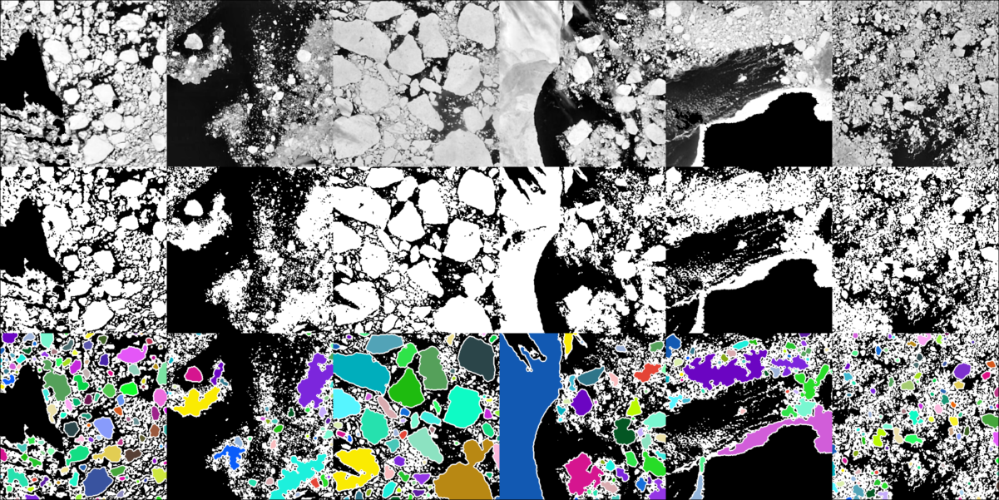

In [15]:
# Find markers by selecting locations greater than dist threshold from background
function distance_markers(binary_floes; dist_threshold=3, strel=se_disk(3))
    bw = .!binary_floes
    dist = distance_transform(feature_transform(bw))
    markers = opening(dist .> dist_threshold, strel)  # or opening?
    markers .= .!imfill(.!markers, (0, 2000))
    return markers
end
@time begin
    floes_cleaned = clean_binary_floes.(adaptive_result, prelim_ice_mask, cloud_mask)
    floes_opened = distance_markers.(floes_cleaned);
    overlay = [RGB.(Gray.(img)) for img in adaptive_result]
    for idx in range(1, length(overlay))
        cview = view_seg_random(SegmentedImage(fc_masked[idx], label_components(floes_opened[idx])))
        overlay[idx][floes_opened[idx] .> 0] .= cview[floes_opened[idx] .> 0]
    end
end

mosaicview(mosaicview(proc_gray..., nrow=1),
           mosaicview([Gray.(img) for img in adaptive_result], nrow=1),
            mosaicview(overlay..., nrow=1))

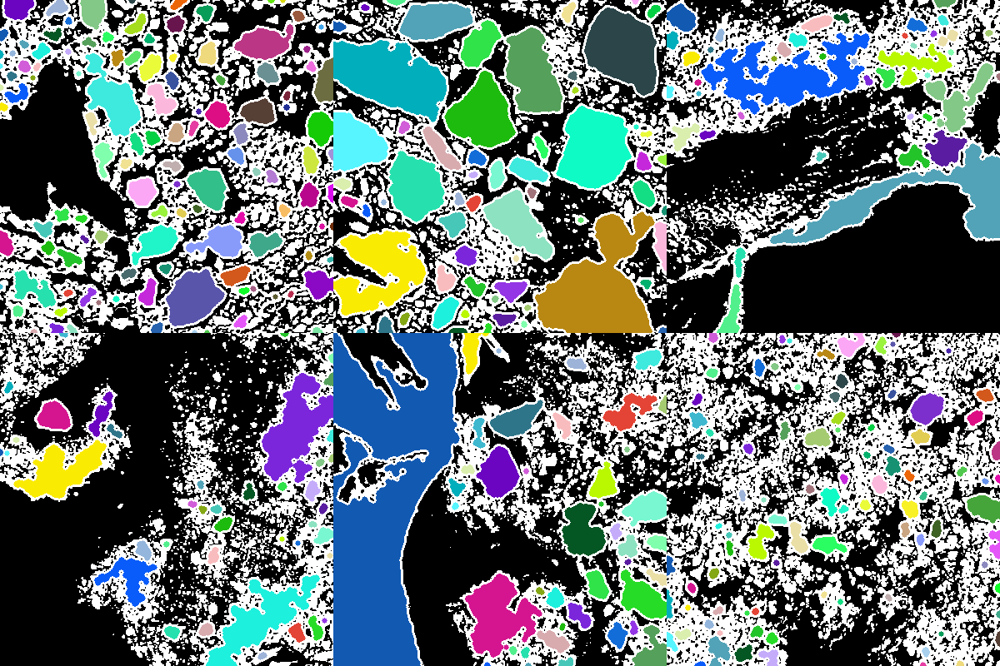

In [24]:
mosaicview(mosaicview(overlay..., nrow=2))

## Option 2: Use the floe-split routine from LA2019 to identify markers

  3.695781 seconds (29.30 M allocations: 1.549 GiB, 4.69% gc time, 90.46% compilation time)


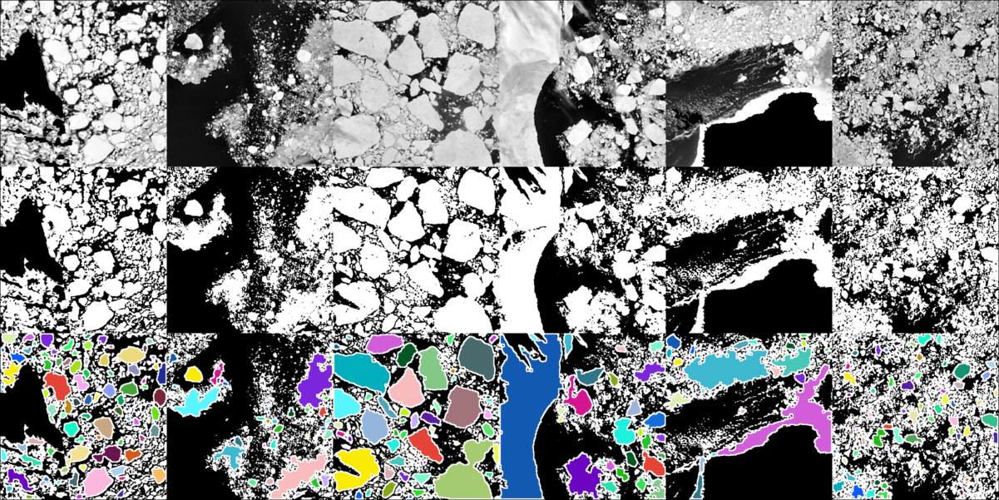

In [16]:
@time begin
    floes_opened = morph_split_floes.(adaptive_result);
end

overlay = [RGB.(Gray.(img)) for img in adaptive_result]
overlay = [RGB.(Gray.(img)) for img in adaptive_result]
for idx in range(1, length(overlay))
    cview = view_seg_random(SegmentedImage(fc_masked[idx], label_components(floes_opened[idx])))
    overlay[idx][floes_opened[idx] .> 0] .= cview[floes_opened[idx] .> 0]
end

mosaicview(mosaicview(proc_gray..., nrow=1),
           mosaicview([Gray.(img) for img in adaptive_result], nrow=1),
            mosaicview(overlay..., nrow=1))

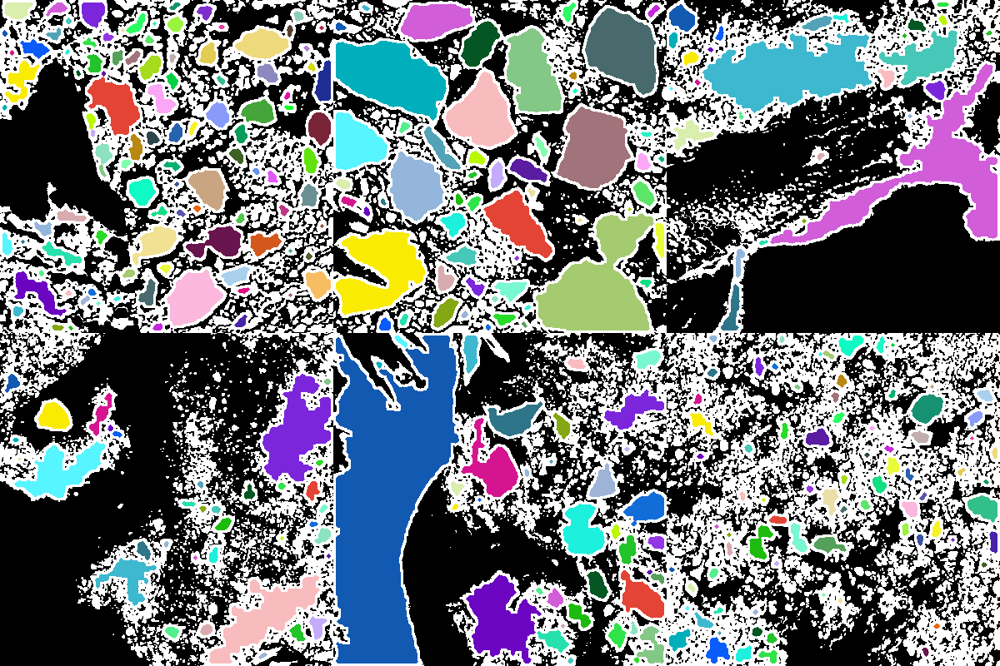

In [17]:
mosaicview(mosaicview(overlay..., nrow=2))

In [186]:
"""
    component_solidities(indexmap)

Compute the solidity (area/convex area) for each labeled region in indexmap. 

"""
function component_solidities(indexmap)
    ca = component_convex_areas(indexmap; algorithm=IceFloeTracker.PixelConvexArea())
    a = component_lengths(indexmap)
    labels = intersect(keys(a), keys(ca))
    s = Dict(r => (r == 0 ? 0 : a[r] / ca[r]) for r in labels)
    return s
end

"""
    component_circularities(indexmap)

Compute the circularity (4πA/P^2)for each labeled region in indexmap. 

"""
function component_circularities(indexmap)
    p = component_perimeters(indexmap)
    a = component_lengths(indexmap)
    labels = intersect(keys(a), keys(p))
    c = Dict(r => (r == 0 ? 0 : 4*π*a[r] / p[r]^2) for r in labels)
    return c
end


# df = regionprops_table(SegmentedImage(fc_masked[1], label_components(floes_opened[1])))
# df[:, :solidity] .= df[:, :area] ./ df[:, :convex_area]
# df[:, :circularity] .= 4 * π .* df[:, :area] ./ df[:, :perimeter].^2
# df

component_circularities

In [187]:
prelim_ice = IceDetectionBrightnessPeaksMODIS134(band_1_min=0.3)


IceDetectionBrightnessPeaksMODIS134(0.3, 3, 0.01, 64)

  0.388033 seconds (4.62 M allocations: 135.071 MiB, 6.09% gc time, 25.43% compilation time)


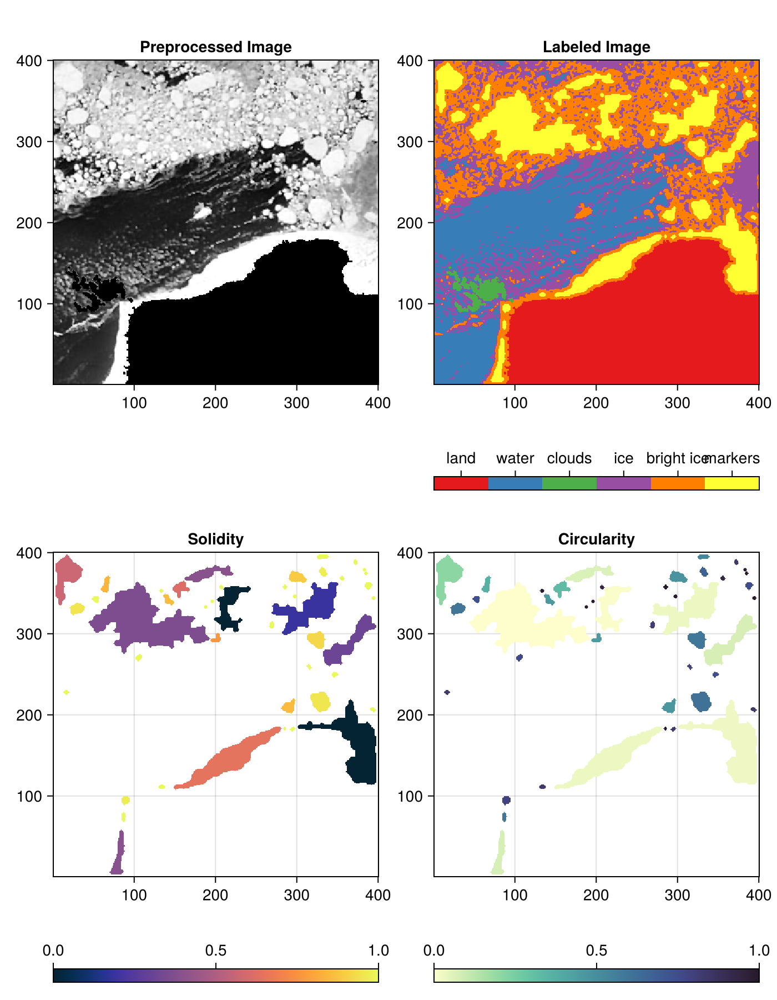

In [188]:
using CairoMakie
idx = 5

# Making the solidity and circularity maps
init_indexmap = label_components(floes_opened[idx])
indices = component_indices(init_indexmap)
solidity_array = zeros(Float64, size(init_indexmap))
circularity_array = zeros(Float64, size(init_indexmap))

@time begin
    solidity = component_solidities(init_indexmap)
    circularity = component_circularities(init_indexmap)
    labels = intersect(keys(solidity), keys(circularity))
    
    for r in labels
        solidity_array[indices[r]] .= solidity[r]
        circularity_array[indices[r]] .= circularity[r]
    end
end
nothing


proc_img = proc_gray[idx]
prelim_ice_mask = prelim_ice(apply_landmask(truecolor_image[idx], land_mask[idx] .|| cloud_mask[idx]))
f = Figure(size=(700, 900))
n, m = size(proc_img)

#### Preprocessed Image
ax1 = CairoMakie.Axis(f[1, 1], title="Preprocessed Image", aspect=m/n,
    ylabel="", xlabel="") # xticks=range(0, 1, 5))
CairoMakie.heatmap!(ax1, rotr90(proc_img), colormap=(:grays, 1.0), colorrange=(0, 1))

#### Classified Image ####
labeled_image = Int64.(.!land_mask[idx]) # land = 1, water = 0
labeled_image[cloud_mask[idx] .> 0] .= 2 # clouds
labeled_image[prelim_ice_mask .> 0] .= 3 # ice
labeled_image[kmeans_result[idx] .> 0] .= 4 # potential floes
labeled_image[floes_opened[idx] .> 0] .= 5 # Markers
ax2 = CairoMakie.Axis(f[1, 2], title="Labeled Image", aspect=m/n,
    ylabel="", xlabel="") 
CairoMakie.heatmap!(ax2, rotr90(labeled_image), colormap=:Set1_6)

Colorbar(f[2, 2], limits = (0, 6), 
    ticks = ([0.5, 1.5, 2.5, 3.5, 4.5, 5.5],
        ["land", "water", "clouds", "ice", "bright ice", "markers"]),
    colormap = cgrad(:Set1_6, 6, categorical = true), vertical=false)

#### Solidity ####
ax3 = CairoMakie.Axis(f[3, 1], title="Solidity", aspect=m/n,
    ylabel="", xlabel="")
plot_arr = deepcopy(rotr90(solidity_array))
plot_arr[plot_arr .== 0] .= NaN
CairoMakie.heatmap!(ax3, plot_arr, colormap=:thermal)
Colorbar(f[4, 1], limits = (0, 1), colormap = :thermal, vertical=false)

#### Circularity ####
ax4 = CairoMakie.Axis(f[3, 2], title="Circularity", aspect=m/n,
    ylabel="", xlabel="")
plot_arr = deepcopy(rotr90(circularity_array))
plot_arr[plot_arr .== 0] .= NaN

CairoMakie.heatmap!(ax4, plot_arr, colormap=:deep)
Colorbar(f[4, 2], limits = (0, 1), colormap = :deep, vertical=false)

current_figure()

## Moving forward



## Using the other k-means clusters
I think there are some straightforward ways we can get a good segmentation result from this. I've tried a handful of methods that didn't actually work, or were too slow to be practical. So I do want to approach this with caution. 
- hole filling: when and where? how large? can we distinguish between cloud holes and ice?

With the cleanup and floe splitting, the best case is that the recall stays high, and the precision increases. Cleanup and splitting will likely only remove false positives; only small changes can be made to the total number of labeled ice floes (excepting the area opening / fill holes algorithm which can be aggressive). 

I need to do something quickly so that we have a dataset to work with.

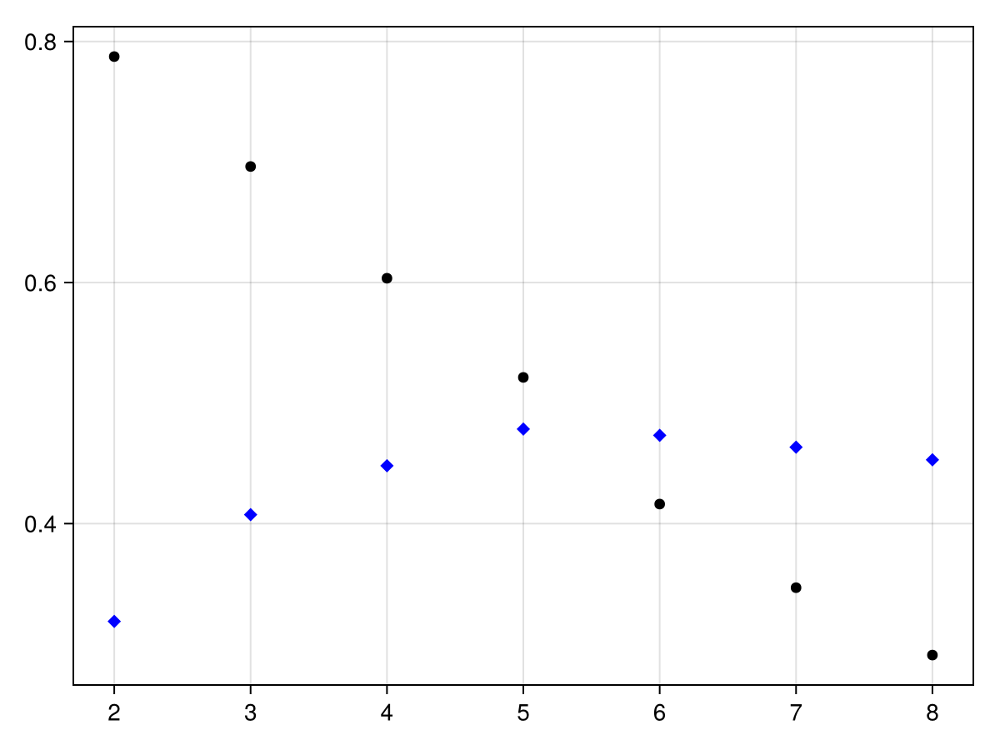

In [135]:
using CairoMakie

fig = Figure()
ax = CairoMakie.Axis(fig[1, 1])

for k in range(2, 8)
    algo = IceDetectionBrightnessPeaksMODIS721(band_7_max=0.1, possible_ice_threshold=0.3; join_method="union")
    kmeans_result = kmeans_binarization.(
            proc_gray,
            fc_masked;
            k=k,
            maxiter=50,
            random_seed=45,
            cluster_selection_algorithm=algo
            );
    validated = validated_labeled_floes.(case)
    measured = SegmentedImage.(proc_gray, label_components.(kmeans_result))
    results = IceFloeTracker.segmentation_comparison.(validated, measured)
    data = Float64.(transpose(stack(collect.(results))))
    results = DataFrame(data, [:recall, :precision, :F_score])

    CairoMakie.scatter!(k, mean(results[:, :recall]), marker=:circle, color=:black)
    CairoMakie.scatter!(k, mean(results[:, :precision]), marker=:diamond, color=:blue)
end
fig

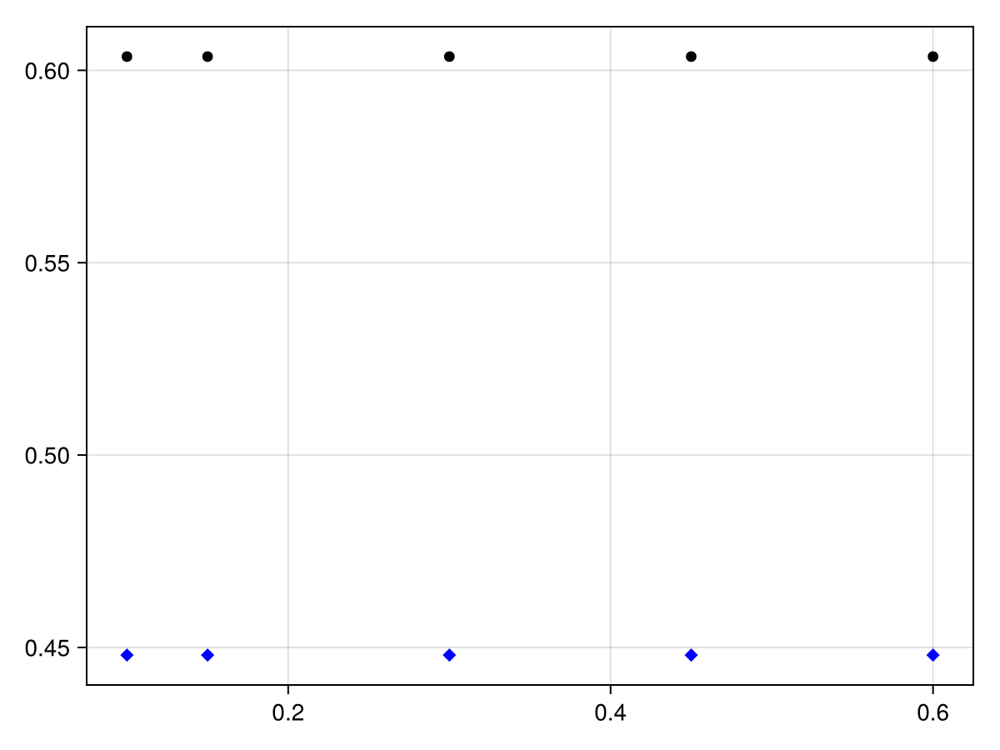

In [137]:
# Possible ice threshold sensitivity

fig = Figure()
ax = CairoMakie.Axis(fig[1, 1])
k = 4
for p in [0.1, 0.15, 0.3, 0.45, 0.6]
    algo = IceDetectionBrightnessPeaksMODIS721(band_7_max=0.1, possible_ice_threshold=p; join_method="union")
    kmeans_result = kmeans_binarization.(
            proc_gray,
            fc_masked;
            k=k,
            maxiter=50,
            random_seed=45,
            cluster_selection_algorithm=algo
            );
    validated = validated_labeled_floes.(case)
    measured = SegmentedImage.(proc_gray, label_components.(kmeans_result))
    results = IceFloeTracker.segmentation_comparison.(validated, measured)
    data = Float64.(transpose(stack(collect.(results))))
    results = DataFrame(data, [:recall, :precision, :F_score])

    CairoMakie.scatter!(p, mean(results[:, :recall]), marker=:circle, color=:black)
    CairoMakie.scatter!(p, mean(results[:, :precision]), marker=:diamond, color=:blue)
end
fig